In this notebook we try to sparsely track the pattern.
The pattern shifts relatively uniform up and right. However displacements are very large which calls for using gaussian pyramids for tracking.

The 100 sparse points to track from are found using the Harris Corner Detector.

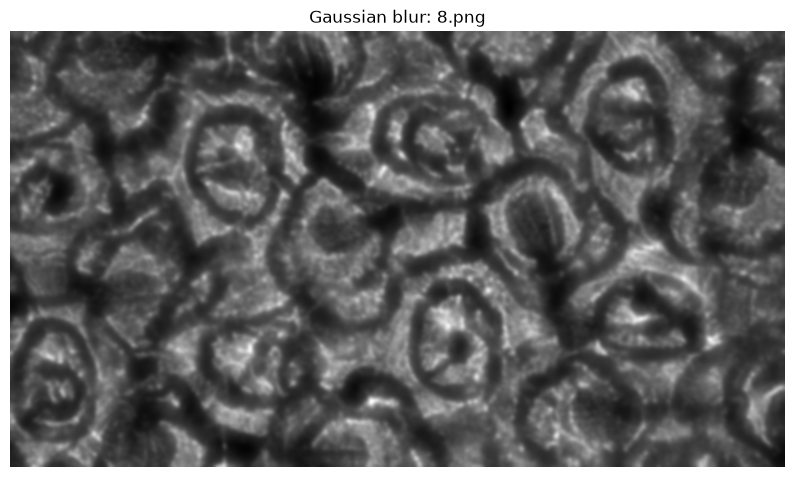

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
IMAGE_NAME = "8.png"
img = cv2.imread(IMAGE_NAME, cv2.IMREAD_GRAYSCALE)

smooth = cv2.GaussianBlur(img, (0, 0), sigmaX=10, sigmaY=10)
# play around with the sigmaX and sigmaY values to see how it affects the smoothing,
# this has a very big effect on the computed gradients

plt.figure(figsize=(10, 6))
plt.imshow(smooth, cmap="gray")
plt.title(f"Gaussian blur: {IMAGE_NAME}")
plt.axis("off")
plt.show()


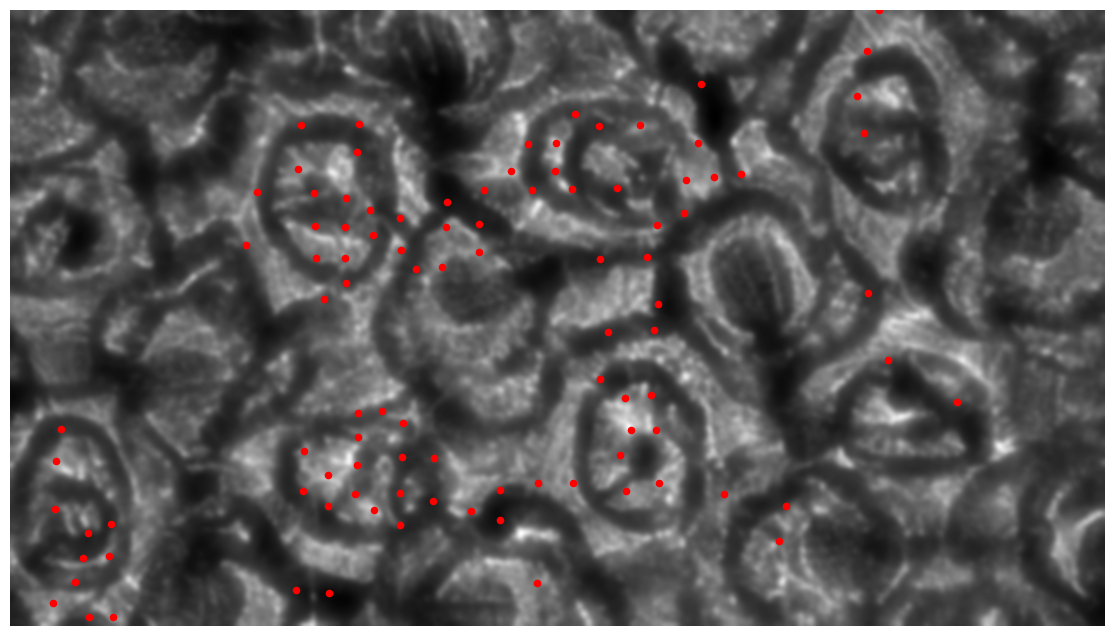

In [24]:
corners = cv2.goodFeaturesToTrack(
    smooth,
    maxCorners=100,
    qualityLevel=0.01,
    minDistance=100,
    blockSize=500,
    useHarrisDetector=False
)

plt.figure(figsize=(15, 8))
plt.imshow(smooth, cmap="gray")

if corners is not None:
    plt.scatter(
        corners[:, 0, 0],
        corners[:, 0, 1],
        s=20,
        c="red"
    )

plt.axis("off")
plt.show()

We again use very large windows/scales to detect a corner.

In [25]:
# Track the previously detected corners in the second grayscale image.
press_img = cv2.imread("8l#.png", cv2.IMREAD_GRAYSCALE)
press_smooth = cv2.GaussianBlur(press_img, (0, 0), sigmaX=10, sigmaY=10)

press_corners, status, error = cv2.calcOpticalFlowPyrLK(
    smooth,
    press_smooth,
    corners,
    None,
    winSize=(501, 501),
    maxLevel=5,
)

tracked = status.ravel() == 1
points0 = corners.reshape(-1, 2)[tracked]
points1 = press_corners.reshape(-1, 2)[tracked]
u = points1[:, 0] - points0[:, 0]
v = points1[:, 1] - points0[:, 1]
displacement = np.hypot(u, v)

print(f"Successfully tracked points: {len(points0)} / {len(corners)}")
if len(points0) > 0:
    print("Displacements in pixels (positive u: right, positive v: down):")
    for name, values in (("u", u), ("v", v), ("magnitude", displacement)):
        print(
            f"{name}: mean={values.mean():.3f}, std={values.std():.3f}, "
            f"median={np.median(values):.3f}, "
            f"min={values.min():.3f}, max={values.max():.3f}"
        )
else:
    print("No successful tracks; displacement statistics are unavailable.")


Successfully tracked points: 99 / 100
Displacements in pixels (positive u: right, positive v: down):
u: mean=10.217, std=78.404, median=9.093, min=-166.853, max=198.538
v: mean=-132.631, std=54.714, median=-121.835, min=-228.225, max=48.883
magnitude: mean=157.348, std=45.586, median=161.352, min=75.295, max=249.186


most corners are succesfully tracked.
algortihm uses no weights to determine structure tensor.
displacements are estimated on blurred images.
consider introducing weights later.

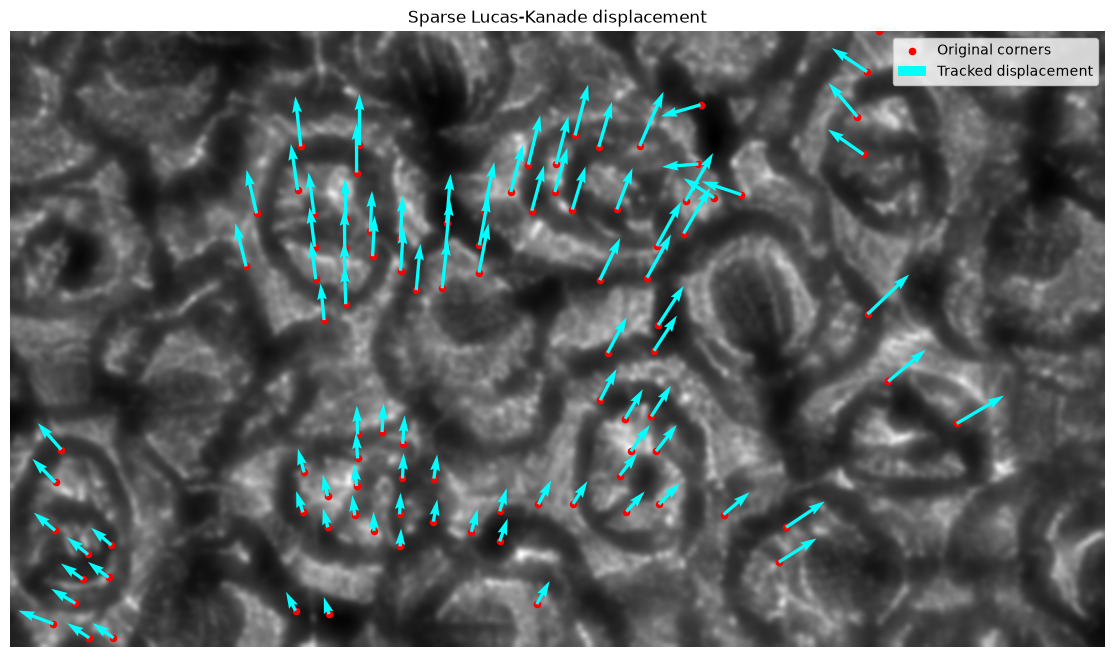

In [26]:
fig, ax = plt.subplots(figsize=(15, 8))
ax.imshow(smooth, cmap="gray", origin="upper")
ax.scatter(
    corners[:, 0, 0], corners[:, 0, 1],
    s=20, c="red", label="Original corners",
)
ax.quiver(
    points0[:, 0], points0[:, 1], u, v,
    angles="xy", scale_units="xy", scale=1,
    color="cyan", width=0.003, pivot="tail",
    label="Tracked displacement",
)
# Image coordinates: x increases rightward and y increases downward.
ax.set_xlim(-0.5, smooth.shape[1] - 0.5)
ax.set_ylim(smooth.shape[0] - 0.5, -0.5)
ax.set_aspect("equal")
ax.set_title("Sparse Lucas-Kanade displacement")
ax.legend(loc="upper right")
ax.axis("off")
plt.show()


Displacements are largely correct.

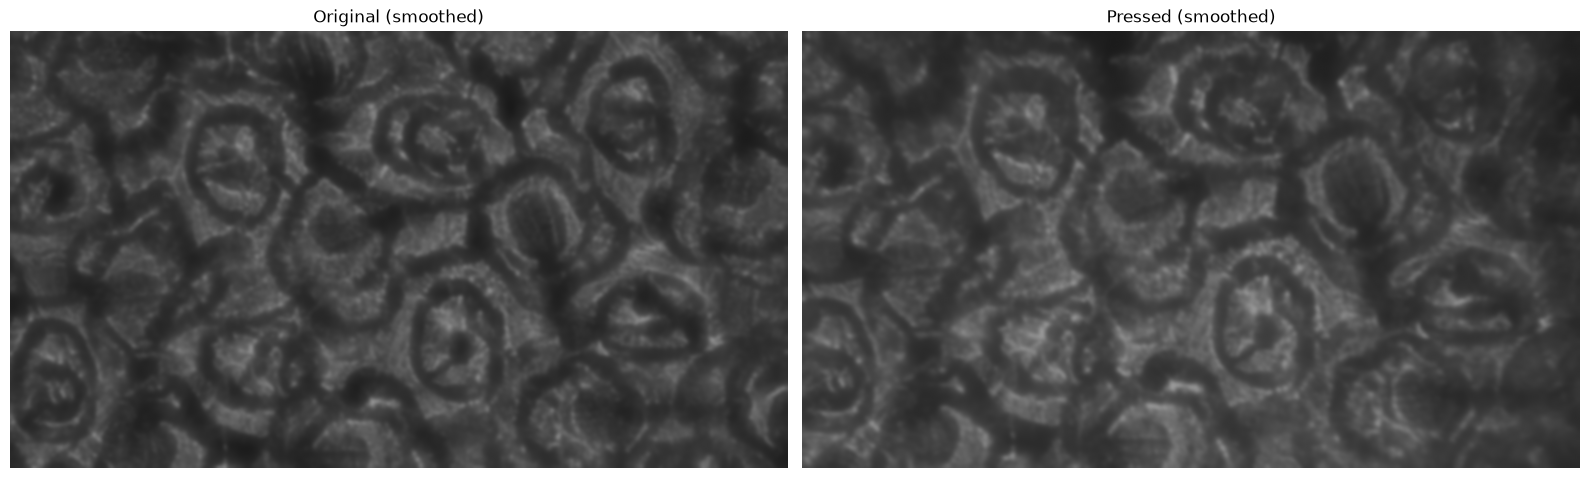

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, image, title in zip(
    axes, (smooth, press_smooth), ("Original (smoothed)", "Pressed (smoothed)")
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255, origin="upper")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


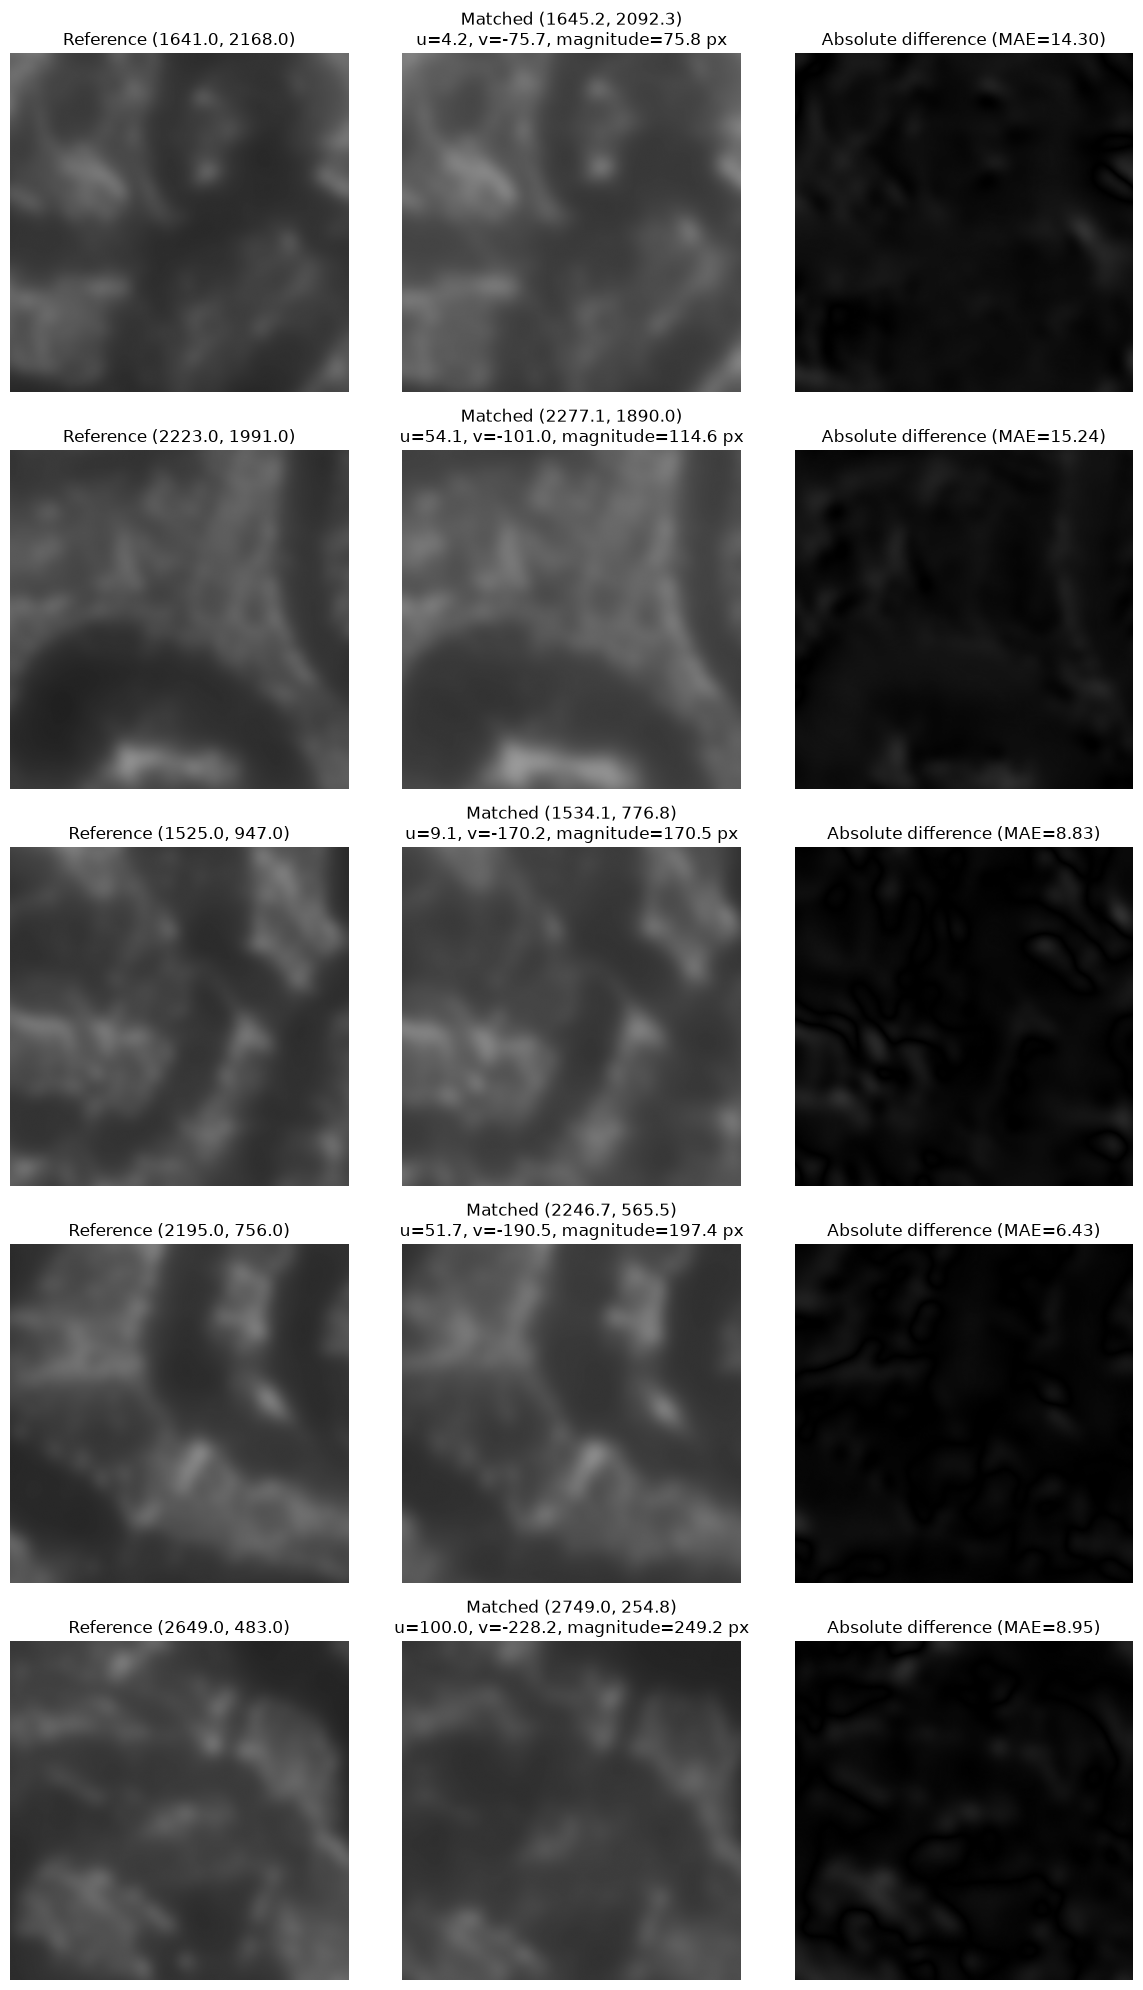

In [28]:
patch_size = (501, 501)
half_patch = 250

# Keep both patches inside their images to avoid padded border pixels.
valid_patches = np.ones(len(points0), dtype=bool)
for points, image in ((points0, smooth), (points1, press_smooth)):
    height, width = image.shape
    valid_patches &= (
        (points[:, 0] >= half_patch)
        & (points[:, 0] <= width - 1 - half_patch)
        & (points[:, 1] >= half_patch)
        & (points[:, 1] <= height - 1 - half_patch)
    )

# Sample across the sorted magnitudes, including the smallest and largest.
patch_candidates = np.flatnonzero(valid_patches)
patch_candidates = patch_candidates[np.argsort(displacement[patch_candidates])]
num_patches = min(5, len(patch_candidates))
if num_patches == 0:
    print("No successful tracks with full 201x201 patches in both images.")
else:
    selected_indices = patch_candidates[
        np.linspace(0, len(patch_candidates) - 1, num_patches, dtype=int)
    ]
    fig, axes = plt.subplots(num_patches, 3, figsize=(12, 4 * num_patches), squeeze=False)
    for row, index in enumerate(selected_indices):
        # getRectSubPix preserves the subpixel centers estimated by LK.
        reference_patch = cv2.getRectSubPix(
            smooth, patch_size, tuple(map(float, points0[index])),
            patchType=cv2.CV_32F,
        )
        matched_patch = cv2.getRectSubPix(
            press_smooth, patch_size, tuple(map(float, points1[index])),
            patchType=cv2.CV_32F,
        )
        difference_patch = np.abs(reference_patch - matched_patch)
        x0, y0 = points0[index]
        x1, y1 = points1[index]
        titles = (
            f"Reference ({x0:.1f}, {y0:.1f})",
            f"Matched ({x1:.1f}, {y1:.1f})\n"
            f"u={u[index]:.1f}, v={v[index]:.1f}, magnitude={displacement[index]:.1f} px",
            f"Absolute difference (MAE={difference_patch.mean():.2f})",
        )
        for ax, patch, title in zip(
            axes[row], (reference_patch, matched_patch, difference_patch), titles
        ):
            ax.imshow(patch, cmap="gray", vmin=0, vmax=255, origin="upper")
            ax.set_title(title)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


I like this visualization because it shows what patches the algorithm is actually looking at. Its usually a good idea for the algorithm to look at features we as humans also tend to look at. 500x500 seems to be the correct scale. And seem to be on a scale that could be sampled by photodiodes.